In [1]:
import numpy as np
import pandas as pd

from sklearn.datasets import (load_diabetes,load_breast_cancer,load_digits,load_iris)
from sklearn.model_selection import train_test_split
from sklearn.metrics import (mean_squared_error,r2_score,accuracy_score,confusion_matrix,precision_recall_fscore_support)

In [2]:
# 1. Diabetes dataset
diabetes = load_diabetes(scaled=False)
X_diabetes = diabetes.data
y_diabetes = diabetes.target

# 2. Breast Cancer dataset
breast_cancer = load_breast_cancer()
X_breast = breast_cancer.data
y_breast = 1 - breast_cancer.target

# 3. Digits dataset
digits = load_digits()
X_digits = digits.data / 16.0
y_digits = digits.target

# 4. Iris dataset
iris = load_iris()
X_iris = iris.data
y_iris = iris.target


In [4]:
def split_dataset(X, y, classification=True):

    #20% for testing
    stratify_value = y if classification else None
    
    X_temp, X_test, y_temp, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=stratify_value)


    #25% of the remaining 80% for validation
    stratify_value = y_temp if classification else None

    X_train, X_val, y_train, y_val = train_test_split(
        X_temp,
        y_temp,
        test_size=0.25,
        random_state=42,
        stratify=stratify_value)

    return X_train, X_val, X_test, y_train, y_val, y_test


diabetes_split = split_dataset(X_diabetes, y_diabetes, classification=False)
breast_split = split_dataset(X_breast, y_breast)
digits_split = split_dataset(X_digits, y_digits)
iris_split = split_dataset(X_iris, y_iris)


In [5]:
datasets = {
    "Diabetes": diabetes_split,
    "Breast Cancer": breast_split,
    "Digits": digits_split,
    "Iris": iris_split
}

for name, split in datasets.items():

    X_train, X_val, X_test, y_train, y_val, y_test = split

    print("\n", name)

    print("Training size:", len(X_train))
    print("Validation size:", len(X_val))
    print("Testing size:", len(X_test))
    print("Total size:", len(X_train) + len(X_val) + len(X_test))

    if name != "Diabetes":
        print("\nTraining class counts:",
              np.unique(y_train, return_counts=True))

        print("Validation class counts:",
              np.unique(y_val, return_counts=True))

        print("Testing class counts:",
              np.unique(y_test, return_counts=True))




 Diabetes
Training size: 264
Validation size: 89
Testing size: 89
Total size: 442

 Breast Cancer
Training size: 341
Validation size: 114
Testing size: 114
Total size: 569

Training class counts: (array([0, 1]), array([214, 127]))
Validation class counts: (array([0, 1]), array([71, 43]))
Testing class counts: (array([0, 1]), array([72, 42]))

 Digits
Training size: 1077
Validation size: 360
Testing size: 360
Total size: 1797

Training class counts: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([106, 109, 107, 109, 109, 109, 109, 107, 104, 108]))
Validation class counts: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([36, 37, 35, 37, 36, 36, 36, 36, 35, 36]))
Testing class counts: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([36, 36, 35, 37, 36, 37, 36, 36, 35, 36]))

 Iris
Training size: 90
Validation size: 30
Testing size: 30
Total size: 150

Training class counts: (array([0, 1, 2]), array([30, 30, 30]))
Validation class counts: (array([0, 1, 2]), array([10, 10, 10]))
Testing class c

In [ ]:
class Standardizer:

    def fit(self, X):
        self.mean = np.mean(X, axis=0)
        self.std = np.std(X, axis=0)
        self.std[self.std == 0] = 1  #avoid devision by 0
        return self

    def transform(self, X):
        return (X - self.mean) / self.std

    

In [8]:
def add_bias(X):
        # Add a column of ones at the beginning
        return np.column_stack((np.ones(X.shape[0]), X))

In [9]:
X_train, X_val, X_test, y_train, y_val, y_test = diabetes_split

scaler = Standardizer()
scaler.fit(X_train)

X_train_std = scaler.transform(X_train)
X_val_std = scaler.transform(X_val)
X_test_std = scaler.transform(X_test)

print("Training means:")
print(np.mean(X_train_std, axis=0))

print("\nTraining standard deviations:")
print(np.std(X_train_std, axis=0))

X_train_bias = add_bias(X_train_std)

print("\nShape before adding bias:", X_train_std.shape)
print("Shape after adding bias:", X_train_bias.shape)


Training means:
[-2.26249995e-16  1.79990702e-16 -2.23726761e-15 -3.61663561e-16
 -5.88754634e-17 -1.08348348e-17  1.94394164e-16 -4.03717464e-17
  2.03877319e-15 -5.53100810e-16]

Training standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Shape before adding bias: (264, 10)
Shape after adding bias: (264, 11)


In [10]:
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2(y_true, y_pred):

    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_total = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_total)

In [11]:
def confusion_matrix(y, pred, K):
    cm = np.zeros((K, K), dtype=int)
    np.add.at(cm, (y, pred), 1)
    return cm

In [ ]:
def accuracy(y, pred):
    return np.mean(y == pred)


def classification_metrics(cm):

    tp = np.diag(cm)
    fp = np.sum(cm, axis=0) - tp
    fn = np.sum(cm, axis=1) - tp


    # precision = 0 if a class is never predicted
    precision = np.divide(
        tp,
        tp + fp,
        out=np.zeros_like(tp, dtype=float),
        where=(tp + fp) != 0
    )

    recall = np.divide(
        tp,
        tp + fn,
        out=np.zeros_like(tp, dtype=float),
        where=(tp + fn) != 0
    )

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros_like(precision, dtype=float),
        where=(precision + recall) != 0
    )

    macro_precision = np.mean(precision)
    macro_recall = np.mean(recall)
    macro_f1 = np.mean(f1)

    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1
    }

In [ ]:
# Stable Softmax function
def softmax(S):
    m = np.max(S,axis=1,keepdims=True)
    S_shifted = S - m
    exp_scores = np.exp(S_shifted)

    P = exp_scores / np.sum(exp_scores,axis=1,keepdims=True)
    return P

#Stable cross entropy
def cross_entropy_loss(S,y):
    m = np.max(S,axis=1,keepdims=True)
    log_sum_exp = m[:,0] + np.log(np.sum(np.exp(S - m),axis=1))
    correct_scores = S[np.arange(len(y)), y]

    losses = log_sum_exp - correct_scores

    return np.mean(losses)
#Regularized entropy -> takes X_bias
def softmax_loss(X_bias, y, W, lam):
    S = X_bias @ W

    data_loss = cross_entropy_loss(S, y)

    reg_loss = (lam / 2) * np.sum(W[1:, :] ** 2)

    return data_loss + reg_loss


# Deriving the Softmax Gradient

The loss function -> L(W) = -(1/N) * sum_i (log Pi.yi) + (lambda/2) * norm(W1:)

* First part -(1/N) * sum_i (log Pi.yi) :

it is given that dl/ds_i_k = Pi_k - Yi_k  ===> which tells the derivative of the loss with respect to each score

So, for all samples, dL / dS = (1/N) * P-Y

And since S = X_bias * W, Applying the chain rule gives us ===> dL / dW = X_bias.T * dL/dS

Therefore, dL / dW = (1/N) * X_bias.T * (P-Y)

* Second part (lambda/2) * norm(W1:) :

||w1:||^2 = sum_j(sum_i(W_j_i^2))

Then, Lreg = (lambda/2) * sum_j(sum_i(W_j_i^2))

Diffrentiating with respect to one weight gives: dL /dW_j_i = (lambda/2) * 2 * W_j_i = lambda * W_j_i

And since we regularize weights without the bias => dL/dW = lambda * [0 W1:]T

* Combining both derivatives => dL/dW = (1/N) * X_bias.T * (P-Y) + lambda * [0 W1:]T


In [ ]:
def softmax_gradient(X_bias, y, W, lam):
    N = len(y)

    #Calculate scores -> we ahve to calculate scores every time as the weights are being updated
    S = X_bias @ W

    P = softmax(S)
    
    Y = np.zeros_like(P)
    Y[np.arange(N), y] = 1
    
    grad = (X_bias.T @ (P - Y)) / N

    #Adding regularization gradient
    grad[1:, :] += lam * W[1:, :]

    return grad

In [ ]:
#testing softmax invariance -> softmax(s + c·1) = softmax(s)
s1 = np.array([[1.0, 2.0, 3.0]])
s2 = np.array([[101.0, 102.0, 103.0]])

print(softmax(s1))
print(softmax(s2))

[[0.09003057 0.24472847 0.66524096]]
[[0.09003057 0.24472847 0.66524096]]


* So, adding a constant to the scores won't affect the probablities

In [ ]:
#No overflow test -> because we normalized the scores
scores = np.array([[1000.0, 1001.0, 1002.0]])

probabilities = softmax(scores)

print(probabilities)
print("Sum:", np.sum(probabilities))

[[0.09003057 0.24472847 0.66524096]]
Sum: 0.9999999999999999


* No overflow happened as we normalized the scores (Subtracted the maximum score of each image)

In [ ]:
# W=0 test -> the regularization term = 0 , pure cross entropy loss
W_zero = np.zeros((65, 10))

loss = softmax_loss(
    X_train_bias,
    y_train,
    W_zero,
    lam=0.1
)

print("Calculated loss:", loss)
print("Expected loss:", np.log(10))

Calculated loss: 2.3025850929940463
Expected loss: 2.302585092994046


* If weights = 0 ,This means lambda is multiplied by 0 which makes the regularization term vanishes causing pure cross entropy loss (No weights to penelize)

In [ ]:
def grad_check(X_bias, y, lam=0.1):
    rng = np.random.default_rng(42)

    W = rng.normal(0, 0.01, size=(X_bias.shape[1], 10))

    analytical_grad = softmax_gradient(X_bias, y, W, lam)

    # Selecting 100 random weight positions
    indices = rng.choice(W.size, size=100, replace=False)

    epsilon = 1e-5
    errors = []
    for idx in indices:
        i, j = np.unravel_index(idx, W.shap)

        # Calculating loss with W[i,j] increased
        W_plus = W.copy()
        W_plus[i, j] += epsilon
        loss_plus = softmax_loss(X_bias, y, W_plus, lam)

        # Calculating loss with W[i,j] decreased
        W_minus = W.copy()
        W_minus[i, j] -= epsilon
        loss_minus = softmax_loss(X_bias, y, W_minus, lam)

        # Numerical gradient
        numerical_grad = (loss_plus - loss_minus) / (2 * epsilon)

        # Analytical gradient for this weight
        analytical = analytical_grad[i, j]

        # Relative error
        error = abs(numerical_grad - analytical) / max(
            1e-8, abs(numerical_grad) + abs(analytical)
        )

        errors.append(error)
    max_error = max(errors)

    print("Maximum relative error:", max_error)

    assert max_error < 1e-6, "Gradient check failed!"



grad_check(X_train_bias, y_train, lam=0.1)

Maximum relative error: 2.2536881201127445e-07


* Gradient check passed ,as relative error is < 1e-6.

In [ ]:

def train_softmax(X_train_bias, y_train,
                  X_val_bias, y_val,
                  eta, lam, epochs=100, batch_size=64):

    N = len(y_train)

    K = len(np.unique(y_train))
    W = np.zeros((X_train_bias.shape[1], K))

    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    for epoch in range(epochs):

        # Shuffle training data
        indices = np.random.permutation(N)

        X_shuffled = X_train_bias[indices]
        y_shuffled = y_train[indices]

        # Mini-batch training
        for start in range(0, N, batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            grad = softmax_gradient(
                X_batch, y_batch, W, lam
            )

            W -= eta * grad

        # batches training ends here(for this epoch) -> all weights are updated for this epoch
        
        # Calculating training loss
        train_loss = softmax_loss(
            X_train_bias, y_train, W, lam
        )

        # Calculating validation loss
        val_loss = softmax_loss(
            X_val_bias, y_val, W, lam
        )

        # Training accuracy
        train_pred = np.argmax(
            softmax(X_train_bias @ W), axis=1
        )

        train_acc = np.mean(train_pred == y_train)

        # Validation accuracy
        val_pred = np.argmax(
            softmax(X_val_bias @ W), axis=1
        )

        val_acc = np.mean(val_pred == y_val)

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accuracies.append(train_acc)
        val_accuracies.append(val_acc)

    return W, train_losses, val_losses, train_accuracies, val_accuracies


In [ ]:
learning_rates = [0.01, 0.1, 0.5, 1.0]

results = {}

for eta in learning_rates:

    # Ensure each experiment uses the same shuffle sequence
    np.random.seed(42)

    W, train_losses, val_losses ,train_accs, val_accs= train_softmax(
        X_train_bias,
        y_train,
        X_val_bias,
        y_val,
        eta=eta,
        lam=0,
        epochs=100,
        batch_size=64
    )

    results[eta] = {
    "W": W,
    "train_losses": train_losses,
    "val_losses": val_losses,
    "train_accs": train_accs,
    "val_accs": val_accs
}

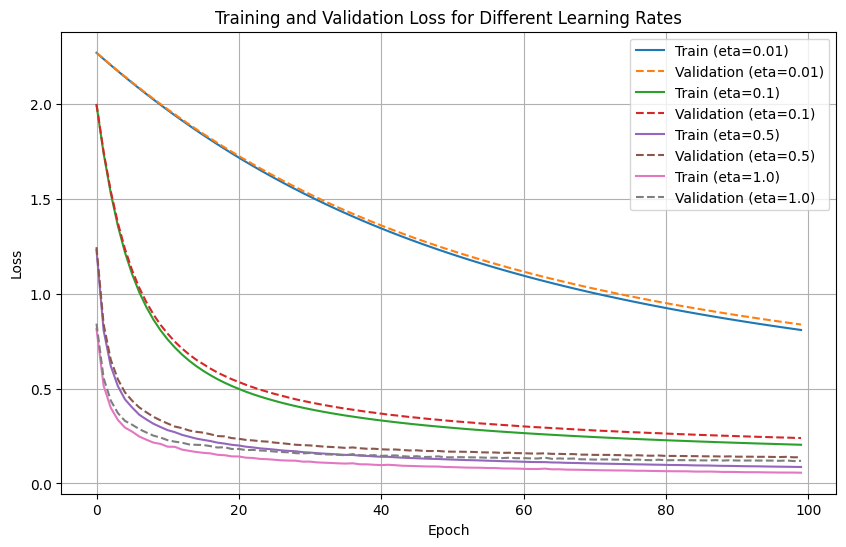

In [ ]:
# Plotting training and validation loss for each learning rate
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

for eta in learning_rates:

    plt.plot(
        results[eta]["train_losses"],
        label=f"Train (eta={eta})"
    )

    plt.plot(
        results[eta]["val_losses"],
        linestyle="--",
        label=f"Validation (eta={eta})"
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss for Different Learning Rates")
plt.legend()
plt.grid()
plt.show()

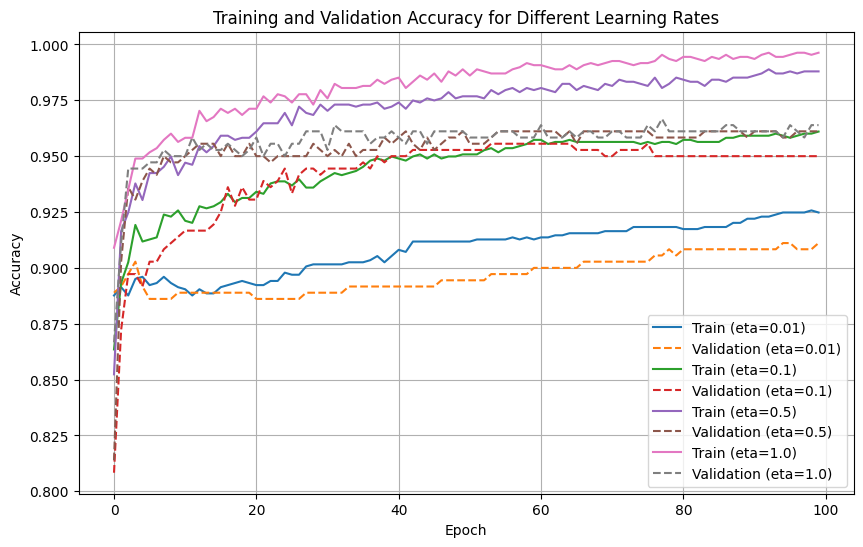

In [ ]:
# Plotting training and validation accuracy for each learning rate

plt.figure(figsize=(10, 6))

for eta in learning_rates:

    plt.plot(
        results[eta]["train_accs"],
        label=f"Train (eta={eta})"
    )

    plt.plot(
        results[eta]["val_accs"],
        linestyle="--",
        label=f"Validation (eta={eta})"
    )

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy for Different Learning Rates")
plt.legend()
plt.grid()
plt.show()

In [ ]:
# Final results for each learning rate

for eta in learning_rates:

    print(f"\nLearning rate: {eta}")
    print(f"Training loss:     {results[eta]['train_losses'][-1]:.4f}")
    print(f"Validation loss:   {results[eta]['val_losses'][-1]:.4f}")
    print(f"Training accuracy: {results[eta]['train_accs'][-1]:.4f}")
    print(f"Validation accuracy: {results[eta]['val_accs'][-1]:.4f}")


Learning rate: 0.01
Training loss:     0.8086
Validation loss:   0.8374
Training accuracy: 0.9248
Validation accuracy: 0.9111

Learning rate: 0.1
Training loss:     0.2038
Validation loss:   0.2391
Training accuracy: 0.9610
Validation accuracy: 0.9500

Learning rate: 0.5
Training loss:     0.0867
Validation loss:   0.1383
Training accuracy: 0.9879
Validation accuracy: 0.9611

Learning rate: 1.0
Training loss:     0.0564
Validation loss:   0.1192
Training accuracy: 0.9963
Validation accuracy: 0.9639


In [ ]:
best_eta = min(
    learning_rates,
    key=lambda eta: results[eta]["val_losses"][-1]
)

print("Best learning rate:", best_eta)
print("Best validation loss:",
      results[best_eta]["val_losses"][-1])

Best learning rate: 1.0
Best validation loss: 0.11920121080117578


With eta=0.01, the model has a relatively high final training loss (0.8086) and validation loss (0.8374), with validation accuracy of 91.11%. This indicates that the model is under-trained after 100 epochs because the learning rate is too small.

Increasing the learning rate improves convergence and classification performance.

The learning rate eta=1.0 achieves the lowest final validation loss (0.1192) and the highest validation accuracy (96.39%) among the tested values.

* Therefore, I select best learning rate =1.0 

In [ ]:
lambdas = [0, 1e-4, 1e-3, 1e-2, 1e-1]

lambda_results = {}

for lam in lambdas:

    np.random.seed(42)

    W, train_losses, val_losses,train_accs, val_accs = train_softmax(
        X_train_bias,
        y_train,
        X_val_bias,
        y_val,
        eta=best_eta,
        lam=lam,
        epochs=100,
        batch_size=64
    )

    # Get final validation accuracy
    val_accuracy = val_accs[-1]

    lambda_results[lam] = {
        "W": W,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "val_accuracy": val_accuracy
    }

    print(f"Lambda: {lam}")
    print(f"Validation loss: {val_losses[-1]:.4f}")
    print(f"Validation accuracy: {val_accuracy:.4f}")
    print("-----------------------------")

Lambda: 0
Validation loss: 0.1192
Validation accuracy: 0.9639
-----------------------------
Lambda: 0.0001
Validation loss: 0.1505
Validation accuracy: 0.9611
-----------------------------
Lambda: 0.001
Validation loss: 0.3033
Validation accuracy: 0.9639
-----------------------------
Lambda: 0.01
Validation loss: 0.7947
Validation accuracy: 0.9389
-----------------------------
Lambda: 0.1
Validation loss: 1.8040
Validation accuracy: 0.6056
-----------------------------


In [ ]:
best_lam = max(
    lambdas,
    key=lambda lam: (lambda_results[lam]["val_accuracy"], lam)
)

best_W = lambda_results[best_lam]["W"]
test_scores = X_test_bias @ best_W
test_probs = softmax(test_scores)

test_predictions = np.argmax(test_probs, axis=1)

test_accuracy = np.mean(test_predictions == y_test)

print("Best lambda: ",best_lam)
print("Test accuracy:", test_accuracy)

Best lambda:  0.001
Test accuracy: 0.9611111111111111



* My Softmax implementation achieves its highest validation accuracy of 96.39%, with a tie between lambda=0 and lambda=0.001 .So, taking the highest best lambda is 0.001.


* At lambda=0.1, my implementation's accuracy drops significantly, indicating that this regularization value is too strong for my training setup.

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
sklearn_results = {}

for lam in lambdas:

    # Convert lambda to C
    if lam == 0:
        C = 1e12
    else:
        C = 1 / (lam * len(y_train))

    # Create the sklearn model
    model = LogisticRegression(
        C=C,
        max_iter=10000
    )

    model.fit(X_train, y_train)

    # Validation predictions
    val_pred = model.predict(X_val)
    val_acc = np.mean(val_pred == y_val)

    # Test predictions
    test_pred = model.predict(X_test)
    test_acc = np.mean(test_pred == y_test)

    sklearn_results[lam] = {
        "model": model,
        "C": C,
        "val_accuracy": val_acc,
        "test_accuracy": test_acc,
        "test_predictions": test_pred
    }

    print(f"Lambda: {lam}")
    print(f"C: {C:.4f}")
    print(f"Validation accuracy: {val_acc:.4f}")
    print(f"Test accuracy: {test_acc:.4f}")
    print("-----------------------------")

Lambda: 0
C: 1000000000000.0000
Validation accuracy: 0.9556
Test accuracy: 0.9556
-----------------------------
Lambda: 0.0001
C: 9.2851
Validation accuracy: 0.9750
Test accuracy: 0.9611
-----------------------------
Lambda: 0.001
C: 0.9285
Validation accuracy: 0.9722
Test accuracy: 0.9556
-----------------------------
Lambda: 0.01
C: 0.0929
Validation accuracy: 0.9472
Test accuracy: 0.9333
-----------------------------
Lambda: 0.1
C: 0.0093
Validation accuracy: 0.9028
Test accuracy: 0.8861
-----------------------------


* Scikit-learn achieves its highest validation accuracy of 97.50% at lambda=0.0001

In [ ]:
print("Comparison: Own Softmax vs sklearn LogisticRegression")

for lam in lambdas:

    print(f"\nLambda: {lam}")

    print("Own validation accuracy:",
          f"{lambda_results[lam]['val_accuracy']:.4f}")

    print("sklearn validation accuracy:",
          f"{sklearn_results[lam]['val_accuracy']:.4f}")

    # Own test accuracy
    own_W = lambda_results[lam]["W"]

    own_test_pred = np.argmax(
        softmax(X_test_bias @ own_W),
        axis=1
    )

    own_test_acc = np.mean(own_test_pred == y_test)

    print("Own test accuracy:",
          f"{own_test_acc:.4f}")

    print("sklearn test accuracy:",
          f"{sklearn_results[lam]['test_accuracy']:.4f}")

Comparison: Own Softmax vs sklearn LogisticRegression

Lambda: 0
Own validation accuracy: 0.9639
sklearn validation accuracy: 0.9556
Own test accuracy: 0.9639
sklearn test accuracy: 0.9556

Lambda: 0.0001
Own validation accuracy: 0.9611
sklearn validation accuracy: 0.9750
Own test accuracy: 0.9611
sklearn test accuracy: 0.9611

Lambda: 0.001
Own validation accuracy: 0.9639
sklearn validation accuracy: 0.9722
Own test accuracy: 0.9611
sklearn test accuracy: 0.9556

Lambda: 0.01
Own validation accuracy: 0.9389
sklearn validation accuracy: 0.9472
Own test accuracy: 0.9222
sklearn test accuracy: 0.9333

Lambda: 0.1
Own validation accuracy: 0.6056
sklearn validation accuracy: 0.9028
Own test accuracy: 0.6389
sklearn test accuracy: 0.8861


* The manual model best lambda is 0.001 while that of the sklearn model is 0.0001.


In [ ]:
# My best model
own_predictions = np.argmax(
    softmax(X_test_bias @ best_W),
    axis=1
)

# sklearn model corresponding to best lambda
sk_model_best = sklearn_results[best_lam]["model"]

sklearn_predictions = sk_model_best.predict(X_test)

# Percentage of matching predictions
agreement = np.mean(
    own_predictions == sklearn_predictions
)

print("Prediction agreement (%):", agreement * 100)



Prediction agreement (%): 99.44444444444444


* Taking the mean of the matching predictions:

* Prediction Agreement =99.44%

* This exceeds 97%, showing that both implementations produce nearly identical predictions on the test set (same prediction on approximately 358 out of 360 test images).

In [ ]:
C_values = [0.1, 1, 10, 100]

C_sweep_results = {}

for C in C_values:

    model = LogisticRegression(C=C, max_iter=10000)
    model.fit(X_train, y_train)

    val_pred = model.predict(X_val)
    test_pred = model.predict(X_test)

    val_acc = np.mean(val_pred == y_val)
    test_acc = np.mean(test_pred == y_test)

    C_sweep_results[C] = {
        "model": model,
        "val_accuracy": val_acc,
        "test_accuracy": test_acc
    }

    print(f"C: {C}")
    print(f"Validation accuracy: {val_acc:.4f}")
    print(f"Test accuracy: {test_acc:.4f}")
    print("-----------------------------")

C: 0.1
Validation accuracy: 0.9500
Test accuracy: 0.9389
-----------------------------
C: 1
Validation accuracy: 0.9722
Test accuracy: 0.9556
-----------------------------
C: 10
Validation accuracy: 0.9639
Test accuracy: 0.9556
-----------------------------
C: 100
Validation accuracy: 0.9611
Test accuracy: 0.9556
-----------------------------


* C = 1 achieved the highest Validation accuracy (97.22%)

In [ ]:
## Confusion matrix
test_scores = X_test_bias @ best_W

test_predictions = np.argmax(
    softmax(test_scores),
    axis=1
)

cm = confusion_matrix(
    y_test,
    test_predictions,
    K=10
)

print(cm)

[[35  0  0  0  1  0  0  0  0  0]
 [ 0 33  0  0  0  1  1  0  1  0]
 [ 0  0 35  0  0  0  0  0  0  0]
 [ 0  0  0 37  0  0  0  0  0  0]
 [ 0  0  0  0 36  0  0  0  0  0]
 [ 0  0  0  0  0 37  0  0  0  0]
 [ 0  0  0  0  0  0 35  0  1  0]
 [ 0  0  0  0  0  0  0 36  0  0]
 [ 0  4  0  0  0  0  0  2 29  0]
 [ 0  0  0  0  2  0  0  0  1 33]]


In [ ]:
# Calculating precision, recall, and F1 for every digit
metrics = classification_metrics(cm)

metrics_table = pd.DataFrame({
    "Digit": range(10),
    "Precision": metrics["precision"],
    "Recall": metrics["recall"],
    "F1-score": metrics["f1"]
})

print(metrics_table.round(4))

print("\nMacro averages:")
print(f"Precision: {metrics['macro_precision']:.4f}")
print(f"Recall:    {metrics['macro_recall']:.4f}")
print(f"F1-score:  {metrics['macro_f1']:.4f}")

   Digit  Precision  Recall  F1-score
0      0     1.0000  0.9722    0.9859
1      1     0.8919  0.9167    0.9041
2      2     1.0000  1.0000    1.0000
3      3     1.0000  1.0000    1.0000
4      4     0.9231  1.0000    0.9600
5      5     0.9737  1.0000    0.9867
6      6     0.9722  0.9722    0.9722
7      7     0.9474  1.0000    0.9730
8      8     0.9062  0.8286    0.8657
9      9     1.0000  0.9167    0.9565

Macro averages:
Precision: 0.9614
Recall:    0.9606
F1-score:  0.9604


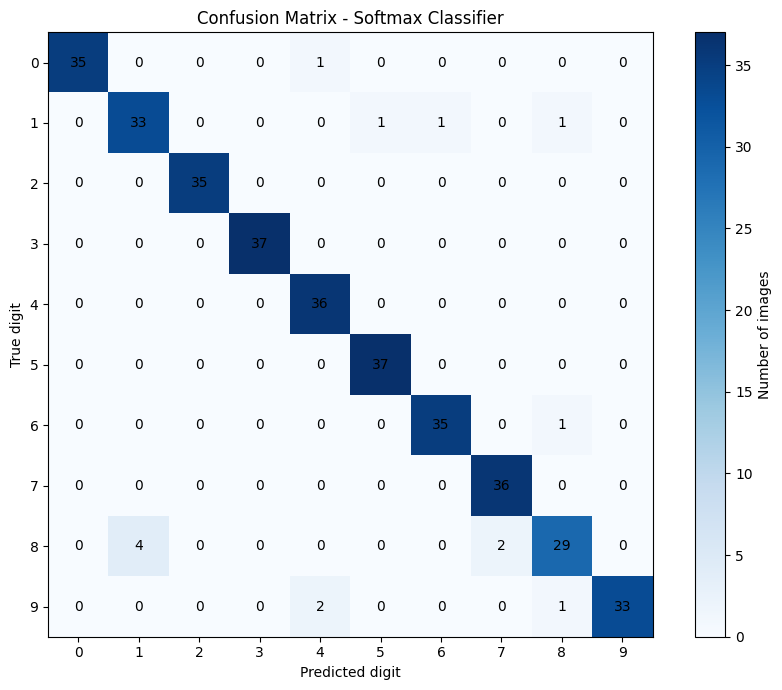

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

plt.imshow(cm, cmap="Blues")

plt.colorbar(label="Number of images")

plt.xticks(range(10))
plt.yticks(range(10))

plt.xlabel("Predicted digit")
plt.ylabel("True digit")
plt.title("Confusion Matrix - Softmax Classifier")

# Display the numbers inside the cells
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j],
                 ha="center",
                 va="center")

plt.tight_layout()
plt.show()

In [ ]:
# Storing incorrect predictions as (true digit, predicted digit, count)
confused_pairs = []

for i in range(10):
    for j in range(10):

        # Ignore the diagonal (correct predictions)
        if i != j and cm[i, j] > 0:
            confused_pairs.append((i, j, cm[i, j]))

# Sort by count, highest first
confused_pairs.sort(key=lambda x: x[2], reverse=True)

# Display the three most confused pairs
print("Top 3 most confused pairs:")

for true_digit, predicted_digit, count in confused_pairs[:3]:
    print(
        f"True digit: {true_digit}, "
        f"Predicted digit: {predicted_digit}, "
        f"Count: {count}"
    )

Top 3 most confused pairs:
True digit: 8, Predicted digit: 1, Count: 4
True digit: 8, Predicted digit: 7, Count: 2
True digit: 9, Predicted digit: 4, Count: 2


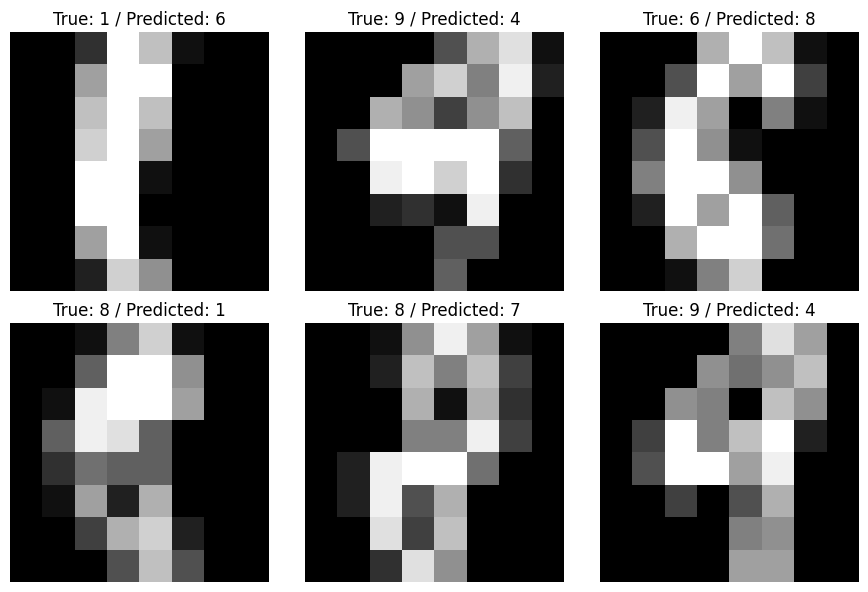

In [ ]:
# Finding indices of incorrectly classified images
misclassified = np.where(y_test != test_predictions)[0]

# Selecting the first six
selected_errors = misclassified[:6]

fig, axes = plt.subplots(2, 3, figsize=(9, 6))

for ax, idx in zip(axes.ravel(), selected_errors):

    ax.imshow(X_test[idx].reshape(8, 8), cmap="gray")

    ax.set_title(
        f"True: {y_test[idx]} / Predicted: {test_predictions[idx]}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

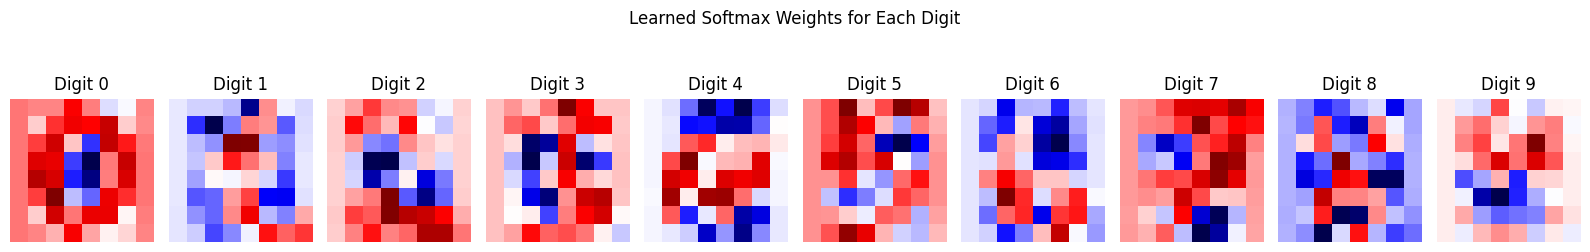

In [ ]:
fig, axes = plt.subplots(1, 10, figsize=(16, 3))

for k in range(10):

    # Get weights for digit k, excluding bias
    digit_weights = best_W[1:, k]

    # Reshape 64 weights into an 8x8 image
    weight_image = digit_weights.reshape(8, 8)

    axes[k].imshow(weight_image, cmap="seismic")
    axes[k].set_title(f"Digit {k}")
    axes[k].axis("off")

plt.suptitle("Learned Softmax Weights for Each Digit")
plt.tight_layout()
plt.show()

Digit 8 is the hardest class to recognize, having the lowest recall (82.86%) and F1-score (86.57%), with most of its errors being classified as digit 1 or 7. Digit 1 is also relatively difficult, with a precision of 89.19%, because some other digits are incorrectly predicted as 1. Digit 9 is sometimes confused with digits 4 and 8, while digit 6 is occasionally confused with digit 8. These errors make sense because the Softmax classifier is linear and uses fixed weights for individual pixel positions, so it cannot fully capture variations in complex shapes, and relationships between pixels.

#  Mathematical Proof that Softmax with K = 2 is Logistic regression 

For a Softmax classifier, the probability of class \(k\) is:
 
P( y= k | x_bias) = e^(x_bias.T * W_k) / sum_j (e^(x_bias.T * W_j)) 

we have only two classes: 0 and 1.

So, The Probability of Class 1 for example is :

P( y= 1 | x_bias) = e^(x_bias.T * W_1) / ( e^(x_bias.T * W_1) + e^(x_bias.T * W_0) ) 

= P( y= 1 | x_bias) = 1 /  e^(x_bias.T * W_0 - x_bias.T * W_1) + 1  ==> Dividing by e^(x_bias.T * W_1)

= P( y= 1 | x_bias) = 1 /  e^(- x_bias.T *( W_1 -  W_0)) + 1 ==> Taking (- x_bias.T) as Common Factor in the exponent


* That is equivalent to 1 / 1 + e^(- z) ==> Sigmoid function with z = x_bias.T *( W_1 -  W_0)

 P( y= 1 | x_bias) = Sigmoid (x_bias.T *( W_1 -  W_0))

* Which proves that two-class Softmax is equivalent to Logistic Regression.

In [ ]:
# Verifying the Equivalence Numerically

X_bc_train, X_bc_val, X_bc_test, y_bc_train, y_bc_val, y_bc_test = breast_split
bc_scaler = Standardizer().fit(X_bc_train)
X_bc_test_std = bc_scaler.transform(X_bc_test)

X_bc_test_bias = add_bias(X_bc_test_std)


#Generating a random matrix
rng = np.random.default_rng(42)
W_binary = rng.normal(
    0, 0.12,
    size=(31, 2)
)

# Calculating probablities using softmax
S_binary = X_bc_test_bias @ W_binary
P_softmax = softmax(S_binary)

p1_softmax = P_softmax[:, 1]

# Implementing the mathematical formula
w_difference = W_binary[:, 1] - W_binary[:, 0]
z = X_bc_test_bias @ w_difference
p1_sigmoid = 1 / (1 + np.exp(-z))

differences = np.abs(p1_softmax - p1_sigmoid)

max_difference = np.max(differences)
print("Maximum probability difference:", max_difference)


Maximum probability difference: 2.220446049250313e-16


* Maximum difference < 10^-12. So, This confirms numerically that two-class Softmax is equivalent to Logistic Regression

In [ ]:
## Iris Dataset test

X_iris_train, X_iris_val, X_iris_test, y_iris_train, y_iris_val, y_iris_test = iris_split

X_iris_train = X_iris_train[:, 2:4]
X_iris_val = X_iris_val[:, 2:4]
X_iris_test = X_iris_test[:, 2:4]

iris_scaler = Standardizer().fit(X_iris_train)
X_iris_train_std = iris_scaler.transform(X_iris_train)
X_iris_val_std = iris_scaler.transform(X_iris_val)
X_iris_test_std = iris_scaler.transform(X_iris_test)

X_iris_train_bias = add_bias(X_iris_train_std)
X_iris_val_bias = add_bias(X_iris_val_std)
X_iris_test_bias = add_bias(X_iris_test_std)

iris_lambdas = [0, 1]

iris_results = {}

for lam in iris_lambdas:

    W, train_losses, val_losses, train_accs, val_accs = train_softmax(
        X_iris_train_bias,
        y_iris_train,
        X_iris_val_bias,
        y_iris_val,
        eta=0.5,
        lam=lam,
        epochs=2000,
        batch_size=len(y_iris_train)
    )

    iris_results[lam] = {
        "W": W,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "train_accs": train_accs,
        "val_accs": val_accs
    }

    print(f"\nLambda = {lam}")
    print("Training accuracy:", train_accs[-1])
    print("Validation accuracy:", val_accs[-1])
    print("Training loss:", train_losses[-1])
    print("Validation loss:", val_losses[-1])


Lambda = 0
Training accuracy: 0.9777777777777777
Validation accuracy: 0.9333333333333333
Training loss: 0.046961806695251046
Validation loss: 0.1712143339046571

Lambda = 1
Training accuracy: 0.8666666666666667
Validation accuracy: 0.8333333333333334
Training loss: 0.9059586201589588
Validation loss: 0.9081831073170141


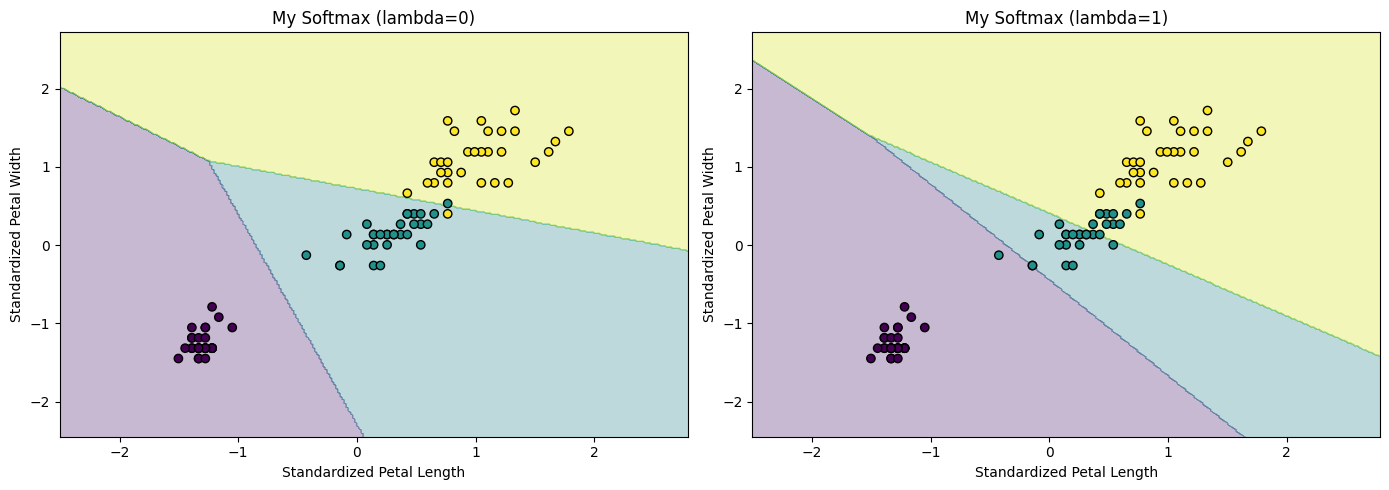

In [ ]:
## Plotting Boundaries
def predict_softmax_grid(grid, W):
    grid_bias = add_bias(grid)
    scores = grid_bias @ W
    probabilities = softmax(scores)
    predictions = np.argmax(probabilities, axis=1)
    return predictions

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, lam in zip(axes, iris_lambdas):

    W = iris_results[lam]["W"]

    x_min, x_max = X_iris_train_std[:, 0].min() - 1, X_iris_train_std[:, 0].max() + 1
    y_min, y_max = X_iris_train_std[:, 1].min() - 1, X_iris_train_std[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    Z = predict_softmax_grid(grid, W)
    Z = Z.reshape(xx.shape)

    # Plotting decision regions
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")

    # Plotting training points
    ax.scatter(
        X_iris_train_std[:, 0],
        X_iris_train_std[:, 1],
        c=y_iris_train,
        edgecolors="black",
        cmap="viridis"
    )

    ax.set_xlabel("Standardized Petal Length")
    ax.set_ylabel("Standardized Petal Width")
    ax.set_title(f"My Softmax (lambda={lam})")

plt.tight_layout()
plt.show()

* λ = 0 (left): The model has no regularization. Its training accuracy is 97.78%, and validation accuracy is 93.33%.



* λ = 1 (right): Regularization penalizes large weights. The decision boundaries change, and the model has lower training and validation accuracy (86.67% and 83.33%).

In [ ]:
from sklearn.linear_model import LogisticRegression

iris_sklearn_results = {}

C_values = {
    0: 1e12,
    1: 1 / len(y_iris_train)
}

for lam, C in C_values.items():

    model = LogisticRegression(
        C=C,
        max_iter=10000
    )

    model.fit(X_iris_train_std, y_iris_train)

    iris_sklearn_results[lam] = model

    print(f"\nLambda = {lam}, C = {C}")
    print("Training accuracy:", model.score(X_iris_train_std, y_iris_train))
    print("Validation accuracy:", model.score(X_iris_val_std, y_iris_val))


Lambda = 0, C = 1000000000000.0
Training accuracy: 0.9777777777777777
Validation accuracy: 0.9333333333333333

Lambda = 1, C = 0.011111111111111112
Training accuracy: 0.8666666666666667
Validation accuracy: 0.8333333333333334


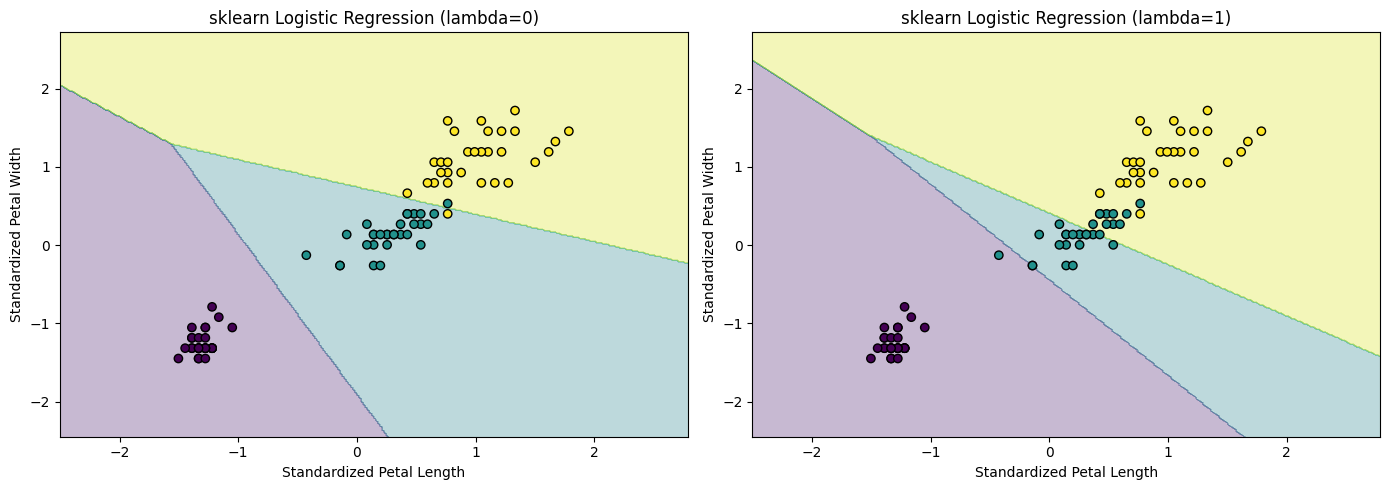

In [ ]:
## Plotting sklearn model Boundaries

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, lam in zip(axes, iris_lambdas):

    model = iris_sklearn_results[lam]

    # Create the mesh grid
    x_min, x_max = X_iris_train_std[:, 0].min() - 1, X_iris_train_std[:, 0].max() + 1
    y_min, y_max = X_iris_train_std[:, 1].min() - 1, X_iris_train_std[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    # Predict using sklearn
    Z = model.predict(grid)
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")

    ax.scatter(
        X_iris_train_std[:, 0],
        X_iris_train_std[:, 1],
        c=y_iris_train,
        edgecolors="black",
        cmap="viridis"
    )

    ax.set_xlabel("Standardized Petal Length")
    ax.set_ylabel("Standardized Petal Width")
    ax.set_title(f"sklearn Logistic Regression (lambda={lam})")

plt.tight_layout()
plt.show()

* The scikit-learn's LogisticRegression model's training and validation accuracies matched those of the Softmax implementation for both regularization settings.

* The decision-region plots from both implementations are very similar. Increasing λ changes the decision boundaries, showing how regularization affects the model's predictions and decision regions.